In [5]:
# Setup module: load packages
import QuantLib as ql
import pandas as pd
import matplotlib.pyplot as plt
import datetime as dt
import sys
from IPython.display import display
from pathlib import Path

from pathlib import Path
import pandas as pd
import QuantLib as ql


In [6]:
# Load data
# Find the repository root
def find_repo_root():
    path = Path.cwd().resolve()

    for parent in [path, *path.parents]:
        if (parent / "requirements.txt").exists():
            return parent

    raise FileNotFoundError(
        "Repository root could not be found. "
        "Make sure you are running this notebook from within the repository."
    )


# Define repository paths
repo_root = find_repo_root()
data_directory = repo_root / "data"
setup_directory = repo_root / "courses" / "setup"

# Load data
euribor_file = data_directory / "6M EURIBOR 20260820.xlsx"
ESTR_file = data_directory / "ESTR 20260820.xlsx"

ESTR_data = pd.read_excel(
    ESTR_file,
    sheet_name="Data",
    skiprows=0
)

# Set the QuantLib evaluation date
ql.Settings.instance().evaluationDate = ql.Date(20, 8, 2026)

# Bootstrap the ESTR curve using setup4.py
%run "$setup_directory/setup4.py"

ESTR curve constructed and ready to use. Setup complete


# Fixed rate bonds in QuantLib
You can create and price fixed rate bonds in QuantLib using the ql.FixedRateBond() function. This function takes a few arguments:
- settlementDays
- faceAmount, the notional of the bond
- cash flow schedule, a ql.Schedule() object that contains the cash flow dates
- a coupon rate, passed as a list
- a payment convention. 

Before we can construct the bond, we first need to create the ql.Schedule() object. This object is a series of ql.Date() objects that is created automatically based on the following parameters:
- issueDate: the date the bond is issued
- unadjusted maturity date, where unadjusted means that if it falls on a weekend day, it's not adjusted to be a business day
- a payment frequency, which indicates how often cash flows occur
- a calendar, such that the cash flows are modified and do not fall on non-business days
- payment conventions
- date generation. Backward date generation means that the coupon dates are set based on the maturity date, instead of based on the issue date. 
- endOfMonth

Now let's create this ql.Schedule object. 

In [7]:
# Bond parameters
calendar = ql.TARGET()
issueDate = ql.Date(12,2,2026)
unadjustedMaturityDate   = calendar.advance(issueDate, 10, ql.Years, ql.Unadjusted)
paymentFrequency = ql.Period(ql.Annual)
paymentConvention = ql.ModifiedFollowing 
dateGeneration = ql.DateGeneration.Backward
endOfMonth = False

bond_schedule = ql.Schedule(
    issueDate,
    unadjustedMaturityDate,
    paymentFrequency,
    calendar,
    paymentConvention,
    paymentConvention,
    dateGeneration,
    endOfMonth
)

print(f"Bond cash flow dates: {bond_schedule.dates()}")


Bond cash flow dates: (Date(12,2,2026), Date(12,2,2027), Date(14,2,2028), Date(12,2,2029), Date(12,2,2030), Date(12,2,2031), Date(12,2,2032), Date(14,2,2033), Date(13,2,2034), Date(12,2,2035), Date(12,2,2036))


With this ql.Schedule, we can now create the ql.FixedRateBond(). We create a fixed rate bond of 10 million EUR notional and 5% coupon rate.

In [8]:
settlementDays = 2
faceAmount = 10e6
coupon = 0.05

bond = ql.FixedRateBond(
    settlementDays,
    faceAmount,
    bond_schedule,
    [coupon],
    ql.ActualActual(ql.ActualActual.Bond)
)

print(f"""
Maturity date: {bond.maturityDate()}
""")

# print the bond cash flows
for cf in bond.cashflows():
    print(f"{cf.date()}: EUR {round(cf.amount(),0)}, has ocurred before April 3rd, 2028? {cf.hasOccurred(ql.Date(3,4,2028))}")


Maturity date: February 12th, 2036

February 12th, 2027: EUR 500000.0, has ocurred before April 3rd, 2028? True
February 14th, 2028: EUR 500000.0, has ocurred before April 3rd, 2028? True
February 12th, 2029: EUR 500000.0, has ocurred before April 3rd, 2028? False
February 12th, 2030: EUR 500000.0, has ocurred before April 3rd, 2028? False
February 12th, 2031: EUR 500000.0, has ocurred before April 3rd, 2028? False
February 12th, 2032: EUR 500000.0, has ocurred before April 3rd, 2028? False
February 14th, 2033: EUR 500000.0, has ocurred before April 3rd, 2028? False
February 13th, 2034: EUR 500000.0, has ocurred before April 3rd, 2028? False
February 12th, 2035: EUR 500000.0, has ocurred before April 3rd, 2028? False
February 12th, 2036: EUR 500000.0, has ocurred before April 3rd, 2028? False
February 12th, 2036: EUR 10000000.0, has ocurred before April 3rd, 2028? False


Let's have a better look at the cashflows contained in the bond object. Extract the cashflows from the bond and put them in a table such that you can analyze and plot.

,Date,Plot date,Amount
0,"February 12th, 2027",2027-02-12,500000.0
1,"February 14th, 2028",2028-02-14,500000.0
2,"February 12th, 2029",2029-02-12,500000.0
3,"February 12th, 2030",2030-02-12,500000.0
4,"February 12th, 2031",2031-02-12,500000.0
5,"February 12th, 2032",2032-02-12,500000.0
6,"February 14th, 2033",2033-02-14,500000.0
7,"February 13th, 2034",2034-02-13,500000.0
8,"February 12th, 2035",2035-02-12,500000.0
9,"February 12th, 2036",2036-02-12,500000.0


Text(0, 0.5, 'Cash flow amount (million EUR)')

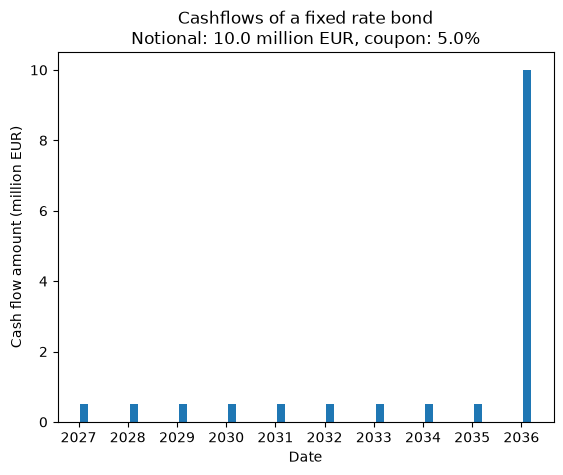

In [9]:
# Extract the cashflows and set it into a table
cashflows = []

for cf in bond.cashflows():
    cashflows.append({
        'Date': cf.date(),
        'Plot date': dt.date(cf.date().year(), cf.date().month(), cf.date().dayOfMonth()),
        'Amount': cf.amount()
    })
cashflows = pd.DataFrame(cashflows)

display(cashflows)

# plot the cashflows
plt.bar(cashflows['Plot date'], cashflows['Amount']/1e6, width=60)
plt.title(f'Cashflows of a fixed rate bond\nNotional: {faceAmount/1e6} million EUR, coupon: {coupon*100}%')
plt.xlabel('Date')
plt.ylabel('Cash flow amount (million EUR)')

So we now have created a fixed rate bond of 5% annual coupon and 10 million notional in QuantLib. The question is, what is the NPV of this bond as of the current evaluation date, which is august 20th, 2026. One way of computing the NPV is by extracting all cash flows from the bond and discount them one by one. As seen in the previous module, the ESTR curve can provide the discount factors for each cash flow. 

However, there's also a build-in function in QuantLib that automatically computes the NPV of the bond using a given discount curve. Let's have a look at both methods and compare the results.

## Bond pricing by discounting the cashflows
We have extracted the cash flows from the bond, so we only need the corresponding discount factors in order to obtain the NPV of all cash flows. The sum of these separate NPVs is the NPV of the bond. 

In the previous module, we've bootstrapped the ESTR curve. In this module, we'll use that curve as discount curve to compute our NPV. In the setup of this module, the ESTR curve is constructed. So it's already available for you to use. Let's get the discount factors!

In [10]:
# Get the discount factor from the ESTR curve based on the cash flow date
cashflows['Discount Factor'] = cashflows['Date'].apply(
    lambda d: ESTR_curve.discount(d)
)

# Compute the NPV of the cash flow using the discount factor
cashflows['NPV'] = cashflows['Amount'] * cashflows['Discount Factor']

display(cashflows)

print(f"The NPV of the bond computed by discounting the cashflows manually is {sum(cashflows['NPV'])}")

,Date,Plot date,Amount,Discount Factor,NPV
0,"February 12th, 2027",2027-02-12,500000.0,0.988053,4.940267e+05
1,"February 14th, 2028",2028-02-14,500000.0,0.960594,4.802972e+05
2,"February 12th, 2029",2029-02-12,500000.0,0.934086,4.670432e+05
3,"February 12th, 2030",2030-02-12,500000.0,0.907853,4.539266e+05
4,"February 12th, 2031",2031-02-12,500000.0,0.881834,4.409168e+05
5,"February 12th, 2032",2032-02-12,500000.0,0.855743,4.278716e+05
6,"February 14th, 2033",2033-02-14,500000.0,0.829220,4.146100e+05
7,"February 13th, 2034",2034-02-13,500000.0,0.803263,4.016315e+05
8,"February 12th, 2035",2035-02-12,500000.0,0.776884,3.884420e+05
9,"February 12th, 2036",2036-02-12,500000.0,0.750534,3.752668e+05


The NPV of the bond computed by discounting the cashflows manually is 11849367.392511385


## Bond pricing using QuantLib pricing engine
In QuantLib, there exists build-in functionality to perform this discounting process for you. This functionality takes four steps:
1. Create a handle that points to a curve object*
2. Create a pricing engine object that uses the curve handle
3. Link you bond with your pricing engine
4. Point your handle to a discount curve of choice. In our case, we'll use ESTR as discount curve.

*in the previous modules, we've used handles for quote objects. However, QuantLib uses handles for more than just quotes. The idea behind the handle is still the same, it's a pointer to an object. If you link the pointer to a new object, the observer pattern understands it and you do not need to change everything. For example, our handle here points to a curve. If you decide to use another curve as discount curve, you just relink your handle and you can go on. No need to recreate the bond engine and link it to the new curve. 

In [11]:
# Create a handle to your discounting curve
discounting_curve_handle = ql.RelinkableYieldTermStructureHandle()              # empty handle, doesn't point to any curve yet

# Create a discounting bond engine
discounting_bond_engine = ql.DiscountingBondEngine(discounting_curve_handle)    # pricing engine linked to a curve handle

# Connect the engine to your bond
bond.setPricingEngine(discounting_bond_engine)                                  # set the pricing engine of your bond

# Select a curve as discount curve and link your handle
discounting_curve_handle.linkTo(ESTR_curve)                                     # link your discount handle to the ESTR curve such that you use the ESTR curve for discounting

Now we're all set to price our bond with the pricing engine. Let's compute the NPV and compare it to the previous result. Any differences?

In [12]:
print(f"The NPV of the bond computed computed with the discounting bond engine in QuantLib is {bond.NPV()}")


The NPV of the bond computed computed with the discounting bond engine in QuantLib is 11849367.392511385


## Assignment
Now it's your turn. Create a 15 year fixed rate bond that is issued on your birthday in 2020. The bond has a notional equal to your age times one million and the coupon rate is set to your favourite percentage in the range of 1-10%. Create the bond and compute it's NPV!

In [13]:
# Your implementation here

# 1: create the cash flow schedule

# 2: create the fixed rate bond

# 3: create the pricing engine and link it to the bond

# 4: compute the NPV